<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/5_2_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!sudo apt-get update
!sudo apt-get install libopencv-dev

Hit:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:2 https://cli.github.com/packages stable InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:8 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:9 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information...

In [ ]:
%%writefile custom_hist.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <vector>
#include <algorithm>

// 1. Kendi Histogram Hesaplama Fonksiyonumuz
// 0'dan 255'e kadar olan piksel değerlerinin görselde kaç kez geçtiğini sayar.
std::vector<int> calculateCustomHist(const cv::Mat& channel) {
    std::vector<int> hist(256, 0); // 256 elemanlı, içi 0 dolu vektör

    for (int r = 0; r < channel.rows; ++r) {
        for (int c = 0; c < channel.cols; ++c) {
            int pixelValue = channel.at<uchar>(r, c); // Pikselin parlaklık değerini al (0-255)
            hist[pixelValue]++; // İlgili parlaklık değerinin sayısını 1 artır
        }
    }
    return hist;
}

int main() {
    std::string imagePath = "image.jpg"; // Görselinin adını gir
    cv::Mat image = cv::imread(imagePath, cv::IMREAD_COLOR);

    if (image.empty()) {
        std::cerr << "Hata: Gorsel yuklenemedi!" << std::endl;
        return -1;
    }

    // 2. Kanalları ayırma
    std::vector<cv::Mat> channels;
    cv::split(image, channels);

    // 3. Kendi fonksiyonumuzla her kanal için histogram hesaplama
    std::vector<int> bHist = calculateCustomHist(channels[0]);
    std::vector<int> gHist = calculateCustomHist(channels[1]);
    std::vector<int> rHist = calculateCustomHist(channels[2]);

    // 4. Histogram Çizimi
    int histW = 512, histH = 400;
    int binW = cvRound((double)histW / 256);
    cv::Mat histImage(histH, histW, CV_8UC3, cv::Scalar(255, 255, 255));

    // Manuel Normalizasyon: Grafiğin tuvale sığması için en yüksek frekans değerini buluyoruz
    int maxVal = 0;
    for (int i = 0; i < 256; i++) {
        maxVal = std::max({maxVal, bHist[i], gHist[i], rHist[i]});
    }

    // Çizgileri çizme ve oranlama (Manuel normalize etme)
    for (int i = 1; i < 256; i++) {
        int bY1 = histH - (int)(((double)bHist[i-1] / maxVal) * histH);
        int bY2 = histH - (int)(((double)bHist[i] / maxVal) * histH);
        int gY1 = histH - (int)(((double)gHist[i-1] / maxVal) * histH);
        int gY2 = histH - (int)(((double)gHist[i] / maxVal) * histH);
        int rY1 = histH - (int)(((double)rHist[i-1] / maxVal) * histH);
        int rY2 = histH - (int)(((double)rHist[i] / maxVal) * histH);

        cv::line(histImage, cv::Point(binW * (i - 1), bY1), cv::Point(binW * i, bY2), cv::Scalar(255, 0, 0), 2);
        cv::line(histImage, cv::Point(binW * (i - 1), gY1), cv::Point(binW * i, gY2), cv::Scalar(0, 255, 0), 2);
        cv::line(histImage, cv::Point(binW * (i - 1), rY1), cv::Point(binW * i, rY2), cv::Scalar(0, 0, 255), 2);
    }

    // Çıktıyı kaydet
    cv::imwrite("custom_histogram.png", histImage);
    std::cout << "Kendi fonksiyonumuzla hesaplanan histogram 'custom_histogram.png' olarak kaydedildi." << std::endl;

    return 0;
}

Overwriting custom_hist.cpp


In [ ]:
!g++ custom_hist.cpp -o custom_hist_program `pkg-config --cflags --libs opencv4`
!./custom_hist_program

Kendi fonksiyonumuzla hesaplanan histogram 'custom_histogram.png' olarak kaydedildi.


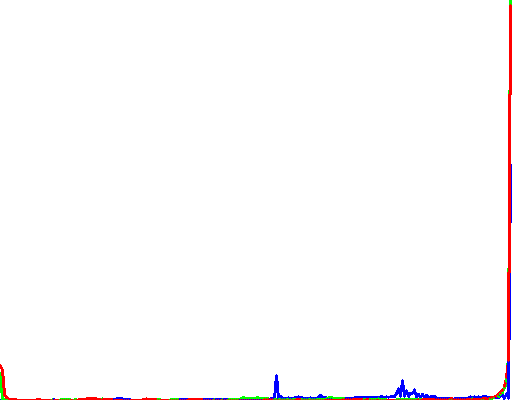

In [ ]:
from IPython.display import Image
Image('custom_histogram.png')